# Lab 2 — Du neurone au perceptron multicouche

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 2**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab se fait **en autonomie, après la séance 2**. Il valide la séance : chaque exemple numérique des diapositives est recalculé ici, puis mis en œuvre sur de petits cas et sur les données de maintenance prédictive du fil rouge A.

## Objectifs

À la fin du lab, vous savez :

1. calculer la sortie d'un **neurone** et d'un **MLP** à la main, puis en NumPy ;
2. entraîner un **perceptron** avec la règle de Rosenblatt, et expliquer pourquoi **XOR** lui échappe ;
3. montrer qu'**une couche cachée** change la représentation et résout XOR ;
4. compter les **paramètres** et les **MAC** d'un réseau, et estimer sa taille mémoire et sa latence sur un STM32F446 ;
5. tracer les **fonctions d'activation** et leurs dérivées, et expliquer la saturation ;
6. choisir une **fonction de perte** (MSE, MAE, Huber, entropie croisée) et pondérer les classes rares ;
7. suivre une **descente de gradient** et voir l'effet du taux d'apprentissage $\eta$.

## Prérequis et environnement

- Python, NumPy, notions de PyTorch (`torch.tensor`, `nn.Linear`).
- **Google Colab gratuit, un CPU suffit.** Durée d'exécution complète : moins d'une minute.

## Plan

| Partie | Contenu |
|---|---|
| 1 | Rappel des formules |
| A | Recalculer les exemples numériques des diapositives |
| B | Expériences : perceptron, XOR, activations, pertes, AI4I, descente de gradient |
| C | Exercices de validation, vérifiés automatiquement |
| | Corrigé |

> **Données** : *AI4I 2020 Predictive Maintenance Dataset* (S. Matzka, 2020), UCI Machine Learning Repository (id 601), licence CC BY 4.0. Jeu **synthétique**, construit pour reproduire le comportement d'un atelier réel.

## 1. Rappel des formules

| Notion | Formule |
|---|---|
| Neurone | $z = \mathbf{w}^\top\mathbf{x} + b$, $\;\hat y = \sigma(z) = \dfrac{1}{1+e^{-z}}$ |
| Perceptron | $\hat y = \mathrm{step}(z)$, $\;\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y-\hat y)\,\mathbf{x}$, $\;b \leftarrow b + \eta\,(y-\hat y)$ |
| Distance à la frontière | $\lvert z\rvert / \lVert\mathbf{w}\rVert$ |
| MLP, forward | $\mathbf{h} = f(W^{[1]}\mathbf{x} + \mathbf{b}^{[1]})$, $\;\hat y = g(W^{[2]}\mathbf{h} + \mathbf{b}^{[2]})$ |
| Paramètres | $P = \sum_\ell (n_{\ell-1}\,n_\ell + n_\ell)$ ; MAC : $\sum_\ell n_{\ell-1}\,n_\ell$ |
| Activations | $\sigma' = \sigma(1-\sigma)$, $\;\tanh' = 1-\tanh^2$, $\;\mathrm{ReLU}(z)=\max(0,z)$, $\;\mathrm{GELU}(z)=z\,\Phi(z)$ |
| Softmax | $p_k = e^{z_k}\big/\sum_j e^{z_j}$ |
| MSE, MAE, Huber | $\tfrac1N\sum e_i^2$, $\;\tfrac1N\sum\lvert e_i\rvert$, $\;H_\delta(e)=\tfrac12e^2$ si $\lvert e\rvert\le\delta$, sinon $\delta(\lvert e\rvert-\tfrac\delta2)$ |
| Entropie croisée | $\mathcal{L}_{\text{BCE}} = -[y\ln p+(1-y)\ln(1-p)]$ ; $\;\mathcal{L}_{\text{CE}} = -\ln p_c$ |
| Perte pondérée | $w_+ = N_0/N_1$ |
| Descente de gradient | $w \leftarrow w - \eta\,\partial\mathcal{L}/\partial w$ |

### Installation et imports

Sur Colab, `numpy`, `pandas`, `matplotlib`, `scikit-learn` et `torch` sont déjà installés.

In [1]:
import math, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
torch.manual_seed(SEED)
T0 = time.time()

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

def echelon(z):
    return (np.asarray(z) >= 0).astype(float)    # step(0) = 1, comme sur les diapositives

## Partie A — Recalculer les exemples des diapositives

Chaque cellule reprend un exemple numérique de la séance et affiche, en commentaire, la valeur écrite sur la diapositive. **Comparez.**

### A.1 Le neurone formel

In [2]:
# Question flash : un neurone sur les 8 entrées d'AI4I (5 mesures + type de produit codé sur 3 colonnes)
n_entrees = 8
n_params = n_entrees + 1
print(f"{n_entrees} poids + 1 biais = {n_params} paramètres = {4 * n_params} octets en float32   (slide : 9 et 36)")

# Neurone formel : x = (2 ; 1), w = (0,5 ; -1), b = 0,5
x = np.array([2.0, 1.0]); w = np.array([0.5, -1.0]); b = 0.5
z = w @ x + b
print(f"z = {z:.1f} ; exp(-z) = {np.exp(-z):.3f} ; y_chapeau = sigma(z) = {sigmoide(z):.3f}   (slide : 0,5 ; 0,607 ; 0,622)")

8 poids + 1 biais = 9 paramètres = 36 octets en float32   (slide : 9 et 36)
z = 0.5 ; exp(-z) = 0.607 ; y_chapeau = sigma(z) = 0.622   (slide : 0,5 ; 0,607 ; 0,622)


### A.2 Le perceptron et sa règle d'apprentissage

In [3]:
def entrainer_perceptron(X, Y, eta=1.0, passages_max=50):
    """Règle de Rosenblatt. Renvoie (w, b, corrections par passage)."""
    w = np.zeros(X.shape[1]); b = 0.0
    historique = []
    for _ in range(passages_max):
        erreurs = 0
        for x, y in zip(X, Y):
            y_hat = float(w @ x + b >= 0)
            if y_hat != y:
                w = w + eta * (y - y_hat) * x
                b = b + eta * (y - y_hat)
                erreurs += 1
        historique.append(erreurs)
        if erreurs == 0:
            break
    return w, b, historique

X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
Y_AND = np.array([0, 0, 0, 1.0]); Y_OR = np.array([0, 1, 1, 1.0]); Y_XOR = np.array([0, 1, 1, 0.0])

# Porte AND calculée à la main : w = (1 ; 1), b = -1,5
print("AND, w = (1 ; 1), b = -1,5 :", echelon(X4 @ np.array([1.0, 1.0]) - 1.5), "  (slide : 0 0 0 1)")

for eta in (1.0, 0.5):
    w, b, h = entrainer_perceptron(X4, Y_AND, eta)
    print(f"AND, eta = {eta} : w = {w}, b = {b}, corrections par passage = {h}, total = {sum(h)}")
print("(slide : eta = 1 → w = (2 ; 1), b = -3, 11 corrections en 5 passages puis un passage sans erreur ;")
print("        eta = 0,5 → mêmes décisions, w = (1 ; 0,5), b = -1,5)")

# Pourquoi z bouge dans le bon sens : z' = z + eta (y - y_hat)(||x||^2 + 1)
w = np.array([0.0, 0.0]); b = -1.0; x = np.array([1.0, 1.0]); y = 1.0; eta = 1.0
z0 = w @ x + b; y_hat = float(z0 >= 0)
w2 = w + eta * (y - y_hat) * x; b2 = b + eta * (y - y_hat); z1 = w2 @ x + b2
print(f"z = {z0}, y_chapeau = {y_hat} → w' = {w2}, b' = {b2}, z' = {z1}  ;  formule : {z0 + eta * (y - y_hat) * (x @ x + 1)}   (slide : z' = 2)")

# Distance d'un point à la frontière
w = np.array([1.0, 1.0]); b = -1.5; x = np.array([1.0, 0.0])
z = w @ x + b
print(f"z = {z}, distance = {abs(z) / np.linalg.norm(w):.3f}   (slide : -0,5 et 0,354)")

AND, w = (1 ; 1), b = -1,5 : [0. 0. 0. 1.]   (slide : 0 0 0 1)
AND, eta = 1.0 : w = [2. 1.], b = -3.0, corrections par passage = [2, 3, 3, 2, 1, 0], total = 11
AND, eta = 0.5 : w = [1.  0.5], b = -1.5, corrections par passage = [2, 3, 3, 2, 1, 0], total = 11
(slide : eta = 1 → w = (2 ; 1), b = -3, 11 corrections en 5 passages puis un passage sans erreur ;
        eta = 0,5 → mêmes décisions, w = (1 ; 0,5), b = -1,5)
z = -1.0, y_chapeau = 0.0 → w' = [1. 1.], b' = 0.0, z' = 2.0  ;  formule : 2.0   (slide : z' = 2)
z = -0.5, distance = 0.354   (slide : -0,5 et 0,354)


### A.3 XOR : aucune droite ne convient, deux droites suffisent

In [4]:
# Meilleur score possible d'un perceptron sur XOR, sur une grille de (w1, w2, b)
g = np.linspace(-3, 3, 61)
W1g, W2g, Bg = np.meshgrid(g, g, g, indexing="ij")
params = np.stack([W1g.ravel(), W2g.ravel(), Bg.ravel()], axis=1)            # 226 981 droites
sorties = echelon(X4 @ params[:, :2].T + params[:, 2])                       # (4, N)
scores = (sorties == Y_XOR[:, None]).sum(axis=0)
print(f"Meilleur score parmi {len(params)} droites : {scores.max()} bonnes réponses sur 4   (slide : au mieux 3 sur 4)")

# Le réseau 2-2-1 de la diapositive : h1 = OU, h2 = ET, sortie = h1 ET NON h2
W1 = np.array([[1.0, 1.0], [1.0, 1.0]]); b1 = np.array([-0.5, -1.5])
W2 = np.array([[1.0, -1.0]]);             b2 = np.array([-0.5])
H = echelon(X4 @ W1.T + b1)
Y_hat = echelon(H @ W2.T + b2).ravel()
print("\n x1 x2 | h1 h2 | y_chapeau")
for x, h, yh in zip(X4, H, Y_hat):
    print(f" {x[0]:.0f}  {x[1]:.0f}  |  {h[0]:.0f}  {h[1]:.0f}  |  {yh:.0f}")

# Forward pour x = (1 ; 0)
x = np.array([1.0, 0.0])
z1 = W1 @ x + b1; h = echelon(z1); z2 = W2 @ h + b2
print(f"\nx = (1 ; 0) : z[1] = {z1}, h = {h}, z[2] = {z2}, y_chapeau = {echelon(z2)}   (slide : (0,5 ; -0,5), (1 ; 0), 0,5, 1)")

Meilleur score parmi 226981 droites : 3 bonnes réponses sur 4   (slide : au mieux 3 sur 4)

 x1 x2 | h1 h2 | y_chapeau
 0  0  |  0  0  |  0
 0  1  |  1  0  |  1
 1  0  |  1  0  |  1
 1  1  |  1  1  |  0

x = (1 ; 0) : z[1] = [ 0.5 -0.5], h = [1. 0.], z[2] = [0.5], y_chapeau = [1.]   (slide : (0,5 ; -0,5), (1 ; 0), 0,5, 1)


### A.4 Paramètres, MAC, mémoire et latence

In [5]:
def compter(couches):
    """couches = [n_0, n_1, ..., n_L] → (paramètres, MAC)."""
    params = sum(a * b + b for a, b in zip(couches[:-1], couches[1:]))
    mac = sum(a * b for a, b in zip(couches[:-1], couches[1:]))
    return params, mac

print("2-2-1     :", compter([2, 2, 1]), "  (slide : 9 paramètres)")
print("3-4-4-2   :", compter([3, 4, 4, 2]), " (slide : 46 paramètres)")

FREQ = 180e6            # STM32F446 : Cortex-M4 à 180 MHz
FLASH = 512 * 1024      # 512 Ko de Flash
for nom, c in (("Couche dense 64 → 32", [64, 32]), ("MLP 8-32-16-1 (AI4I)", [8, 32, 16, 1])):
    p, m = compter(c)
    print(f"{nom:22s} : {p:5d} paramètres, {m:5d} MAC | float32 {4 * p:5d} octets ({100 * 4 * p / FLASH:.1f} % de la Flash), "
          f"int8 {p:5d} octets | latence {2 * m / FREQ * 1e6:.1f} à {4 * m / FREQ * 1e6:.1f} µs")
print("(slide : 2 080 / 2 048 / 8 320 o / 1,6 % / 23 à 46 µs  et  833 / 784 / 3 332 o / 0,6 % / 8,7 à 17 µs)")

# Vérification avec PyTorch
mlp = nn.Sequential(nn.Linear(8, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
print("Paramètres comptés par PyTorch :", sum(p.numel() for p in mlp.parameters()))

# Approximation universelle : deux sigmoïdes font une bosse
print(f"\nsigma(5) - sigma(-5) = {sigmoide(5) - sigmoide(-5):.3f}   (slide : 0,987)")

2-2-1     : (9, 6)   (slide : 9 paramètres)
3-4-4-2   : (46, 36)  (slide : 46 paramètres)
Couche dense 64 → 32   :  2080 paramètres,  2048 MAC | float32  8320 octets (1.6 % de la Flash), int8  2080 octets | latence 22.8 à 45.5 µs
MLP 8-32-16-1 (AI4I)   :   833 paramètres,   784 MAC | float32  3332 octets (0.6 % de la Flash), int8   833 octets | latence 8.7 à 17.4 µs
(slide : 2 080 / 2 048 / 8 320 o / 1,6 % / 23 à 46 µs  et  833 / 784 / 3 332 o / 0,6 % / 8,7 à 17 µs)
Paramètres comptés par PyTorch : 833

sigma(5) - sigma(-5) = 0.987   (slide : 0,987)


### A.5 Activations

In [6]:
# Sans non-linéarité, deux couches linéaires se réduisent à une seule
W1 = np.array([[1.0, 2.0], [0.0, 1.0]]); W2 = np.array([[1.0, 0.0], [-1.0, 1.0]]); x = np.array([1.0, 1.0])
print("W1 x =", W1 @ x, "; W2 (W1 x) =", W2 @ (W1 @ x))
print("W2 W1 =", (W2 @ W1).tolist(), "; (W2 W1) x =", (W2 @ W1) @ x, "  (slide : (3 ; 1), (3 ; -2), [[1 2],[-1 -1]], (3 ; -2))")

# Valeurs en trois points
print("\n z  | sigma   sigma'    tanh    tanh'")
for v in (0, 2, 5):
    s = sigmoide(v)
    print(f" {v}  | {s:.3f}  {s * (1 - s):.5f}  {math.tanh(v):.3f}  {1 - math.tanh(v) ** 2:.6f}")
print("(slide : 0,5 / 0,25 / 0 / 1 ; 0,881 / 0,105 / 0,964 / 0,0707 ; 0,993 / 0,00665 / 1,00 / 0,000182)")
print(f"0,25^10 = {0.25 ** 10:.3g}   (slide : 9,54e-7)")

# ReLU, Leaky ReLU (alpha = 0,01) et GELU en z = -1 et z = 1
def gelu(z):  return z * 0.5 * (1 + math.erf(z / math.sqrt(2)))
def dgelu(z): return 0.5 * (1 + math.erf(z / math.sqrt(2))) + z * math.exp(-z * z / 2) / math.sqrt(2 * math.pi)
print("\n            f(-1)   f'(-1)    f(1)   f'(1)")
print(f"ReLU       {0:6.3f}  {0:6.3f}  {1:6.3f}  {1:6.3f}")
print(f"Leaky      {-0.01:6.3f}  {0.01:6.3f}  {1:6.3f}  {1:6.3f}")
print(f"GELU       {gelu(-1):6.3f}  {dgelu(-1):6.4f}  {gelu(1):6.3f}  {dgelu(1):6.3f}   (slide : -0,159 / -0,0833 / 0,841 / 1,08)")

# Softmax : z = (2 ; 1 ; 0)
z = np.array([2.0, 1.0, 0.0])
e = np.exp(z)
print(f"\nexp(z) = {e}, somme = {e.sum():.3f}, p = {e / e.sum()}   (slide : 7,389 2,718 1 ; 11,107 ; 0,665 0,245 0,090)")
pm = np.exp(z - z.max())
print(f"en soustrayant le maximum : somme = {pm.sum():.3f}, p = {pm / pm.sum()}   (slide : 1,503)")
print(f"float32 : exp(z) déborde dès que z > ln(3,4e38) = {np.log(np.finfo(np.float32).max):.1f}   (slide : 88,7)")

W1 x = [3. 1.] ; W2 (W1 x) = [ 3. -2.]
W2 W1 = [[1.0, 2.0], [-1.0, -1.0]] ; (W2 W1) x = [ 3. -2.]   (slide : (3 ; 1), (3 ; -2), [[1 2],[-1 -1]], (3 ; -2))

 z  | sigma   sigma'    tanh    tanh'
 0  | 0.500  0.25000  0.000  1.000000
 2  | 0.881  0.10499  0.964  0.070651
 5  | 0.993  0.00665  1.000  0.000182
(slide : 0,5 / 0,25 / 0 / 1 ; 0,881 / 0,105 / 0,964 / 0,0707 ; 0,993 / 0,00665 / 1,00 / 0,000182)
0,25^10 = 9.54e-07   (slide : 9,54e-7)

            f(-1)   f'(-1)    f(1)   f'(1)
ReLU        0.000   0.000   1.000   1.000
Leaky      -0.010   0.010   1.000   1.000
GELU       -0.159  -0.0833   0.841   1.083   (slide : -0,159 / -0,0833 / 0,841 / 1,08)

exp(z) = [7.3891 2.7183 1.    ], somme = 11.107, p = [0.6652 0.2447 0.09  ]   (slide : 7,389 2,718 1 ; 11,107 ; 0,665 0,245 0,090)
en soustrayant le maximum : somme = 1.503, p = [0.6652 0.2447 0.09  ]   (slide : 1,503)
float32 : exp(z) déborde dès que z > ln(3,4e38) = 88.7   (slide : 88,7)


### A.6 Trois façons de calculer une sigmoïde sur un microcontrôleur

La diapositive compare trois approximations de $\sigma$ sur $z \in [-8, 8[$. On mesure ici leur erreur maximale sur $10^6$ points.

In [7]:
z = np.linspace(-8, 8, 1_000_001)
exact = sigmoide(z)

# 1) Table de 256 entrées : entrée au pas de 1/16 sur [-8, 8[, valeur prise au centre du pas, sortie sur 8 bits
centres = -8 + (np.arange(256) + 0.5) / 16
table = np.round(sigmoide(centres) * 255) / 255                    # 256 octets en Flash
indice = np.clip(np.floor((z + 8) * 16), 0, 255).astype(int)
err_table = np.max(np.abs(table[indice] - exact))

# 2) PLAN (Amin et al., 1997) : 4 segments de pentes 1/4, 1/8, 1/32, puis saturation à 1
def plan(x):
    a = np.abs(x)
    y = np.where(a >= 5, 1.0,
        np.where(a >= 2.375, 0.03125 * a + 0.84375,
        np.where(a >= 1, 0.125 * a + 0.625, 0.25 * a + 0.5)))
    return np.where(x >= 0, y, 1 - y)
err_plan = np.max(np.abs(plan(z) - exact))

# 3) Hard sigmoïde : clip(z/4 + 1/2, 0, 1)
err_hard = np.max(np.abs(np.clip(z / 4 + 0.5, 0, 1) - exact))

print(f"Table de 256 entrées : erreur max = {err_table:.4f}   (slide : 0,0097)")
print(f"PLAN                 : erreur max = {err_plan:.3f}    (slide : 0,019)")
print(f"Hard sigmoïde        : erreur max = {err_hard:.3f}    (slide : 0,119)")

Table de 256 entrées : erreur max = 0.0097   (slide : 0,0097)
PLAN                 : erreur max = 0.019    (slide : 0,019)
Hard sigmoïde        : erreur max = 0.119    (slide : 0,119)


### A.7 Fonctions de perte

In [8]:
def huber(e, delta=1.0):
    e = np.asarray(e, dtype=float)
    return np.where(np.abs(e) <= delta, 0.5 * e ** 2, delta * (np.abs(e) - delta / 2))

e = np.array([0.5, -0.5, 1.0, 10.0])        # un capteur dont la 4e lecture est aberrante
print(f"Avec l'aberrante : MSE = {np.mean(e ** 2):.3f}, MAE = {np.mean(np.abs(e)):.3f}, Huber = {np.mean(huber(e)):.3f}   (slide : 25,4 ; 3 ; 2,56)")
e3 = e[:3]
print(f"Sans l'aberrante : MSE = {np.mean(e3 ** 2):.3f}, MAE = {np.mean(np.abs(e3)):.3f}, Huber = {np.mean(huber(e3)):.3f}   (slide : 0,5 ; 0,667 ; 0,25)")
print("Poids de chaque point dans la correction (au facteur 1/N près) :")
print("   MSE  2|e| =", 2 * np.abs(e), " | MAE =", np.ones(4), " | Huber min(|e|, 1) =", np.minimum(np.abs(e), 1.0), "  (slide : 20 pour la MSE)")
lectures = np.array([20.0, 21.0, 22.0, 37.0])
print(f"Meilleure constante : moyenne (MSE) = {lectures.mean()}, médiane (MAE) = {np.median(lectures)}   (slide : 25 et 21,5)")

# Entropie croisée binaire, pour une vraie panne (y = 1)
print("\nBCE, y = 1 :", {p: round(-math.log(p), 3) for p in (0.9, 0.5, 0.1, 0.01)}, "  (slide : 0,105 ; 0,693 ; 2,30 ; 4,61)")

# Entropie croisée à 3 classes : logits (2 ; 1 ; 0)
p = np.exp([2.0, 1.0, 0.0]); p = p / p.sum()
print(f"CE, vraie classe « normal » : {-math.log(p[0]):.3f} ; « surchauffe » : {-math.log(p[2]):.3f} ; hasard ln 3 = {math.log(3):.3f}   (slide : 0,408 ; 2,41 ; 1,10)")

# Maximum de vraisemblance : y = (1 ; 0 ; 1), p = (0,9 ; 0,2 ; 0,6)
y = np.array([1, 0, 1]); pp = np.array([0.9, 0.2, 0.6])
vraisemblance = np.prod(pp ** y * (1 - pp) ** (1 - y))
bce = -(y * np.log(pp) + (1 - y) * np.log(1 - pp))
print(f"vraisemblance = {vraisemblance:.3f}, -ln = {-math.log(vraisemblance):.3f}, BCE = {bce.round(3)}, somme = {bce.sum():.3f}   (slide : 0,432 ; 0,839 ; 0,839)")
print(f"10 000 probabilités de 0,9 : ln(produit) = {10000 * math.log(0.9):.0f}, plus petit float64 positif ≈ e^{math.log(5e-324):.0f}   (slide : e^-1054 et e^-744)")

# Classes déséquilibrées : AI4I, 339 pannes sur 10 000 cycles
N1, N0 = 339, 9661
p0 = N1 / (N0 + N1)
print(f"\nw+ = N0/N1 = {N0 / N1:.1f}   (slide : 28,5)")
print(f"Répondre toujours p = {p0:.3f} : BCE moyenne = {-(p0 * math.log(p0) + (1 - p0) * math.log(1 - p0)):.3f}, accuracy du modèle « jamais de panne » = {N0 / (N0 + N1):.1%}   (slide : 0,148 et 96,6 %)")
print(f"Panne manquée (p = 0,1) : {-math.log(0.1):.2f} sans pondération, {28.5 * -math.log(0.1):.1f} avec   (slide : 2,30 et 65,6)")

Avec l'aberrante : MSE = 25.375, MAE = 3.000, Huber = 2.562   (slide : 25,4 ; 3 ; 2,56)
Sans l'aberrante : MSE = 0.500, MAE = 0.667, Huber = 0.250   (slide : 0,5 ; 0,667 ; 0,25)
Poids de chaque point dans la correction (au facteur 1/N près) :
   MSE  2|e| = [ 1.  1.  2. 20.]  | MAE = [1. 1. 1. 1.]  | Huber min(|e|, 1) = [0.5 0.5 1.  1. ]   (slide : 20 pour la MSE)
Meilleure constante : moyenne (MSE) = 25.0, médiane (MAE) = 21.5   (slide : 25 et 21,5)

BCE, y = 1 : {0.9: 0.105, 0.5: 0.693, 0.1: 2.303, 0.01: 4.605}   (slide : 0,105 ; 0,693 ; 2,30 ; 4,61)
CE, vraie classe « normal » : 0.408 ; « surchauffe » : 2.408 ; hasard ln 3 = 1.099   (slide : 0,408 ; 2,41 ; 1,10)
vraisemblance = 0.432, -ln = 0.839, BCE = [0.105 0.223 0.511], somme = 0.839   (slide : 0,432 ; 0,839 ; 0,839)
10 000 probabilités de 0,9 : ln(produit) = -1054, plus petit float64 positif ≈ e^-744   (slide : e^-1054 et e^-744)

w+ = N0/N1 = 28.5   (slide : 28,5)
Répondre toujours p = 0.034 : BCE moyenne = 0.148, accuracy du 

### A.8 Descente de gradient

In [9]:
def descente(eta, k, w0=0.0):
    """k pas de descente de gradient sur f(w) = (w - 3)^2, de dérivée f'(w) = 2 (w - 3). Renvoie la suite w_0 ... w_k."""
    suite = [w0]
    for _ in range(k):
        suite.append(suite[-1] - eta * 2 * (suite[-1] - 3))
    return suite

s = descente(0.1, 3)
print("eta = 0,1 :", np.round(s, 3), " f(w_k) =", np.round((np.array(s) - 3) ** 2, 2), "  (slide : 0 ; 0,6 ; 1,08 ; 1,464 et 9 ; 5,76 ; 3,69 ; 2,36)")
k = next(k for k in range(1, 200) if abs(-3 * 0.8 ** k) < 0.01)
print(f"Itérations pour passer à moins de 0,01 du minimum : {k}   (slide : 26)")
for eta in (0.1, 0.5, 0.9, 1.1):
    print(f"eta = {eta} :", np.round(descente(eta, 5), 2))
print("(slide : 0,5 → minimum en un pas ; 0,9 → 5,4 ; 1,08 ; 4,54 ; 1,77 ; 3,98 ; 1,1 → 6,6 ; -1,32 ; 8,18 ; -3,22 ; 10,5)")

eta = 0,1 : [0.    0.6   1.08  1.464]  f(w_k) = [9.   5.76 3.69 2.36]   (slide : 0 ; 0,6 ; 1,08 ; 1,464 et 9 ; 5,76 ; 3,69 ; 2,36)
Itérations pour passer à moins de 0,01 du minimum : 26   (slide : 26)
eta = 0.1 : [0.   0.6  1.08 1.46 1.77 2.02]
eta = 0.5 : [0. 3. 3. 3. 3. 3.]
eta = 0.9 : [0.   5.4  1.08 4.54 1.77 3.98]
eta = 1.1 : [ 0.    6.6  -1.32  8.18 -3.22 10.46]
(slide : 0,5 → minimum en un pas ; 0,9 → 5,4 ; 1,08 ; 4,54 ; 1,77 ; 3,98 ; 1,1 → 6,6 ; -1,32 ; 8,18 ; -3,22 ; 10,5)


## Partie B — Expériences

### B.1 Un perceptron en NumPy : AND, OR, XOR

On entraîne la même règle sur les trois portes. AND et OR convergent (théorème de Novikoff). XOR ne converge jamais : la règle tourne en rond.

AND : corrections par passage = [2, 3, 3, 2, 1, 0]
OR : corrections par passage = [2, 2, 1, 0]
XOR : corrections par passage = [3, 3, 4, 4, 4, 4, 4, 4] ...


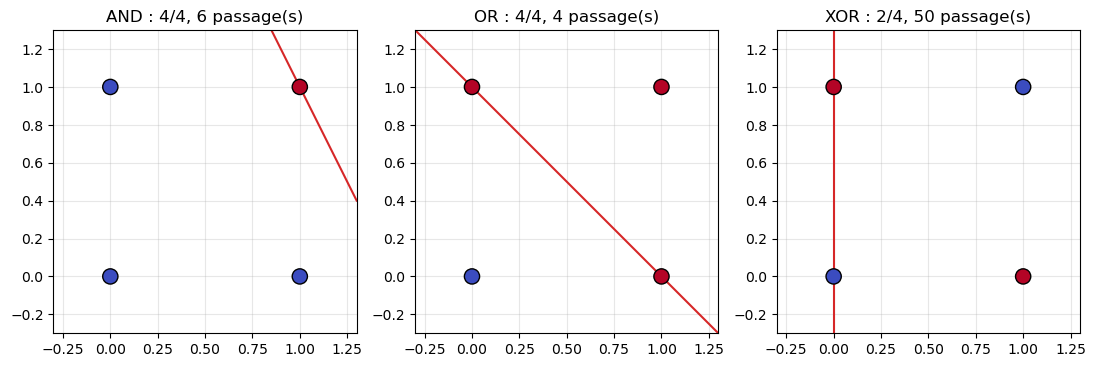

In [10]:
def tracer_frontiere(ax, w, b, titre):
    xs = np.linspace(-0.3, 1.3, 50)
    if abs(w[1]) > 1e-9:
        ax.plot(xs, -(w[0] * xs + b) / w[1], color="C3")
    else:
        ax.axvline(-b / w[0] if abs(w[0]) > 1e-9 else 0, color="C3")
    ax.scatter(X4[:, 0], X4[:, 1], c=y_cible, cmap="coolwarm", s=120, edgecolor="k", zorder=3)
    ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.3); ax.set_title(titre); ax.set_aspect("equal")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (nom, y_cible) in zip(axes, [("AND", Y_AND), ("OR", Y_OR), ("XOR", Y_XOR)]):
    w, b, h = entrainer_perceptron(X4, y_cible, eta=1.0, passages_max=50)
    bonnes = int((echelon(X4 @ w + b) == y_cible).sum())
    tracer_frontiere(ax, w, b, f"{nom} : {bonnes}/4, {len(h)} passage(s)")
    print(f"{nom} : corrections par passage = {h[:8]}{' ...' if len(h) > 8 else ''}")
plt.tight_layout(); plt.show()

**À observer.** Pour XOR le nombre de corrections ne tombe jamais à 0 : au mieux 3 points sur 4 sont bien classés, quelle que soit la droite. C'est le résultat de Minsky et Papert (1969).

### B.2 Une couche cachée change la représentation

On reprend le réseau 2-2-1 fixé à la main (A.3) et on trace l'espace caché $(h_1, h_2)$ : les deux points de classe 1 se confondent en $(1\,;\,0)$, et une seule droite sépare désormais les classes.

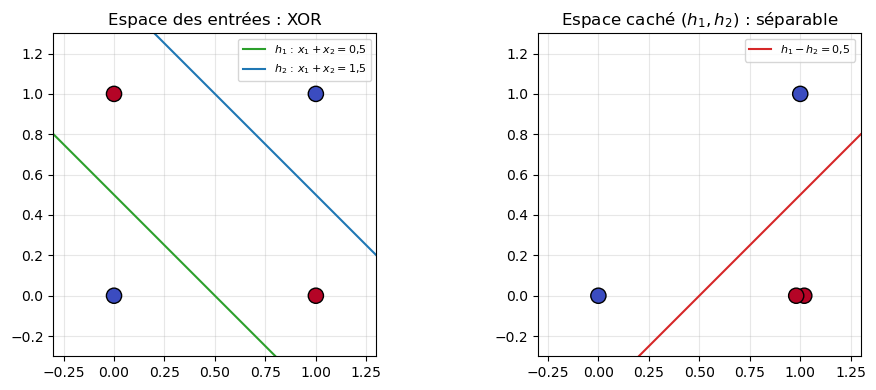

Points de l'espace caché : {(0, 0): (0, 0), (0, 1): (1, 0), (1, 0): (1, 0), (1, 1): (1, 1)}


In [11]:
W1 = np.array([[1.0, 1.0], [1.0, 1.0]]); b1 = np.array([-0.5, -1.5])
W2 = np.array([[1.0, -1.0]]);             b2 = np.array([-0.5])
H = echelon(X4 @ W1.T + b1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
xs = np.linspace(-0.3, 1.3, 50)
axes[0].scatter(X4[:, 0], X4[:, 1], c=Y_XOR, cmap="coolwarm", s=120, edgecolor="k", zorder=3)
axes[0].plot(xs, 0.5 - xs, "C2", label="$h_1$ : $x_1+x_2=0{,}5$")
axes[0].plot(xs, 1.5 - xs, "C0", label="$h_2$ : $x_1+x_2=1{,}5$")
axes[0].set_title("Espace des entrées : XOR"); axes[0].set_xlim(-0.3, 1.3); axes[0].set_ylim(-0.3, 1.3); axes[0].legend(fontsize=8)
axes[1].scatter(H[:, 0] + 0.02 * np.array([0, 1, -1, 0]), H[:, 1], c=Y_XOR, cmap="coolwarm", s=120, edgecolor="k", zorder=3)
axes[1].plot(xs, xs - 0.5, "C3", label="$h_1 - h_2 = 0{,}5$")
axes[1].set_title("Espace caché $(h_1, h_2)$ : séparable"); axes[1].set_xlim(-0.3, 1.3); axes[1].set_ylim(-0.3, 1.3); axes[1].legend(fontsize=8)
for ax in axes: ax.set_aspect("equal")
plt.tight_layout(); plt.show()
print("Points de l'espace caché :", {tuple(int(v) for v in x): tuple(int(v) for v in h) for x, h in zip(X4, H)})

### B.3 Fonctions d'activation et dérivées

Tracez les activations de la séance. La dérivée de la sigmoïde ne dépasse jamais $0{,}25$ : c'est la cause des gradients qui disparaissent (séance 3). Celle de la ReLU vaut 0 ou 1.

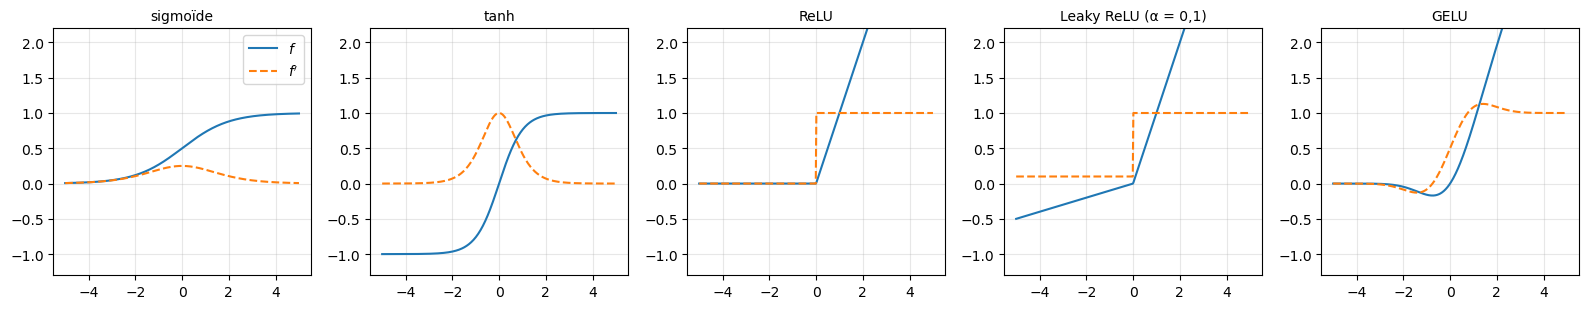

max de sigma'(z) = 0.250   |   max de tanh'(z) = 1.000


In [12]:
zz = np.linspace(-5, 5, 400)
gelu_v = np.array([gelu(v) for v in zz]); dgelu_v = np.array([dgelu(v) for v in zz])
fonctions = {
    "sigmoïde": (sigmoide(zz), sigmoide(zz) * (1 - sigmoide(zz))),
    "tanh":     (np.tanh(zz), 1 - np.tanh(zz) ** 2),
    "ReLU":     (np.maximum(0, zz), (zz > 0).astype(float)),
    "Leaky ReLU (α = 0,1)": (np.where(zz > 0, zz, 0.1 * zz), np.where(zz > 0, 1.0, 0.1)),
    "GELU":     (gelu_v, dgelu_v),
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharex=True)
for ax, (nom, (f, df_)) in zip(axes, fonctions.items()):
    ax.plot(zz, f, label="$f$"); ax.plot(zz, df_, "--", label="$f'$")
    ax.set_title(nom, fontsize=10); ax.set_ylim(-1.3, 2.2)
axes[0].legend()
plt.tight_layout(); plt.show()
print(f"max de sigma'(z) = {np.max(fonctions['sigmoïde'][1]):.3f}   |   max de tanh'(z) = {np.max(fonctions['tanh'][1]):.3f}")

### B.4 MSE, MAE ou Huber : un capteur qui se trompe parfois

On simule 200 lectures de température bruitées, dont 5 % sont aberrantes (un capteur qui décroche). On cherche la constante $c$ qui minimise chaque perte : la MSE suit la moyenne, la MAE suit la médiane, Huber est entre les deux.

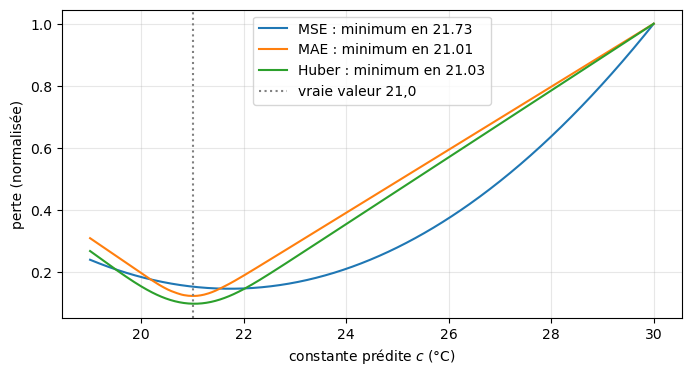

moyenne = 21.73 °C | médiane = 21.01 °C


In [13]:
rng = np.random.default_rng(SEED)
lectures = rng.normal(21.0, 0.5, 200)
lectures[rng.choice(200, 10, replace=False)] = rng.uniform(30, 45, 10)       # 5 % de lectures aberrantes

cs = np.linspace(19, 30, 500)
pertes = {
    "MSE":   [np.mean((lectures - c) ** 2) for c in cs],
    "MAE":   [np.mean(np.abs(lectures - c)) for c in cs],
    "Huber": [np.mean(huber(lectures - c, 1.0)) for c in cs],
}
fig, ax = plt.subplots()
for nom, p in pertes.items():
    p = np.array(p)
    ax.plot(cs, p / p.max(), label=f"{nom} : minimum en {cs[np.argmin(p)]:.2f}")
ax.axvline(21.0, color="gray", ls=":", label="vraie valeur 21,0")
ax.set_xlabel("constante prédite $c$ (°C)"); ax.set_ylabel("perte (normalisée)"); ax.legend()
plt.show()
print(f"moyenne = {lectures.mean():.2f} °C | médiane = {np.median(lectures):.2f} °C")

**À observer.** La moyenne est tirée vers les aberrantes ; la médiane et le minimum de Huber restent près de la vraie valeur. Sur un capteur sujet aux décrochages, MAE ou Huber.

### B.5 Un neurone sur AI4I : l'accuracy trompe, la perte pondérée aide

On entraîne **un seul neurone** (régression logistique : 8 entrées, 9 paramètres) sur les pannes d'AI4I, d'abord avec la BCE ordinaire, puis avec la BCE pondérée par $w_+ = N_0/N_1$. On compare à un modèle « jamais de panne ».

In [14]:
URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
try:
    df = pd.read_csv(URL, compression="zip")
except Exception as e:                      # repli si le site UCI est indisponible
    print("Téléchargement direct impossible :", e)
    try:
        import ucimlrepo
    except ImportError:
        %pip install -q ucimlrepo
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=601)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df.columns = [c.replace("﻿", "").strip() for c in df.columns]
df = df.rename(columns={"Air temperature [K]": "T_air_K", "Process temperature [K]": "T_process_K",
                        "Rotational speed [rpm]": "vitesse_rpm", "Torque [Nm]": "couple_Nm",
                        "Tool wear [min]": "usure_outil_min", "Machine failure": "panne"})
print(df.shape, f"| {df['panne'].sum()} pannes sur {len(df)} cycles ({df['panne'].mean():.1%})")

(10000, 14) | 339 pannes sur 10000 cycles (3.4%)


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

MESURES = ["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "usure_outil_min"]
X_df = pd.concat([df[MESURES], pd.get_dummies(df["Type"]).astype(float)], axis=1)        # 5 mesures + 3 colonnes de type = 8 entrées
y_all = df["panne"].values.astype(np.float32)
X_tr, X_te, y_tr, y_te = train_test_split(X_df.values.astype(np.float32), y_all, test_size=0.2, stratify=y_all, random_state=SEED)
mu, sd = X_tr.mean(0), X_tr.std(0) + 1e-8
X_tr, X_te = (X_tr - mu) / sd, (X_te - mu) / sd
print("entrées :", X_tr.shape[1], "| test :", len(y_te), "cycles dont", int(y_te.sum()), "pannes")

def entrainer_neurone(X, y, pos_weight=None, epochs=600, lr=0.5):
    torch.manual_seed(SEED)
    neurone = nn.Linear(X.shape[1], 1)
    crit = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor([pos_weight]))
    opt = torch.optim.SGD(neurone.parameters(), lr=lr)
    Xt, yt = torch.from_numpy(X), torch.from_numpy(y)
    for _ in range(epochs):
        opt.zero_grad(); loss = crit(neurone(Xt).squeeze(1), yt); loss.backward(); opt.step()
    return neurone

def evaluer(nom, pred):
    print(f"{nom:28s} accuracy = {accuracy_score(y_te, pred):.3f} | précision = {precision_score(y_te, pred, zero_division=0):.3f} | "
          f"rappel = {recall_score(y_te, pred):.3f} | F1 = {f1_score(y_te, pred):.3f}")

w_plus = (y_tr == 0).sum() / (y_tr == 1).sum()
evaluer("jamais de panne", np.zeros_like(y_te))
for nom, pw in (("BCE ordinaire", None), (f"BCE pondérée (w+ = {w_plus:.1f})", float(w_plus))):
    neurone = entrainer_neurone(X_tr, y_tr, pw)
    with torch.no_grad():
        pred = (torch.sigmoid(neurone(torch.from_numpy(X_te))).squeeze(1).numpy() >= 0.5).astype(float)
    evaluer(nom, pred)
    print(" " * 28, "matrice de confusion [[VN FP], [FN VP]] =", confusion_matrix(y_te, pred).tolist())
print("\nParamètres du neurone :", sum(p.numel() for p in neurone.parameters()), "(8 poids + 1 biais)")

entrées : 8 | test : 2000 cycles dont 68 pannes
jamais de panne              accuracy = 0.966 | précision = 0.000 | rappel = 0.000 | F1 = 0.000


BCE ordinaire                accuracy = 0.969 | précision = 0.857 | rappel = 0.088 | F1 = 0.160
                             matrice de confusion [[VN FP], [FN VP]] = [[1931, 1], [62, 6]]
BCE pondérée (w+ = 28.5)     accuracy = 0.826 | précision = 0.142 | rappel = 0.824 | F1 = 0.243
                             matrice de confusion [[VN FP], [FN VP]] = [[1595, 337], [12, 56]]

Paramètres du neurone : 9 (8 poids + 1 biais)


**À observer.** Le modèle « jamais de panne » atteint près de 97 % d'accuracy sans détecter une seule panne. La BCE ordinaire fait à peine mieux. La BCE pondérée détecte la plupart des pannes, au prix de nombreuses fausses alarmes : c'est un compromis, que la séance 3 traite avec le seuil de décision et le F1.

### B.6 Le taux d'apprentissage $\eta$

On suit la descente de gradient sur $f(w) = (w-3)^2$ pour quatre valeurs de $\eta$.

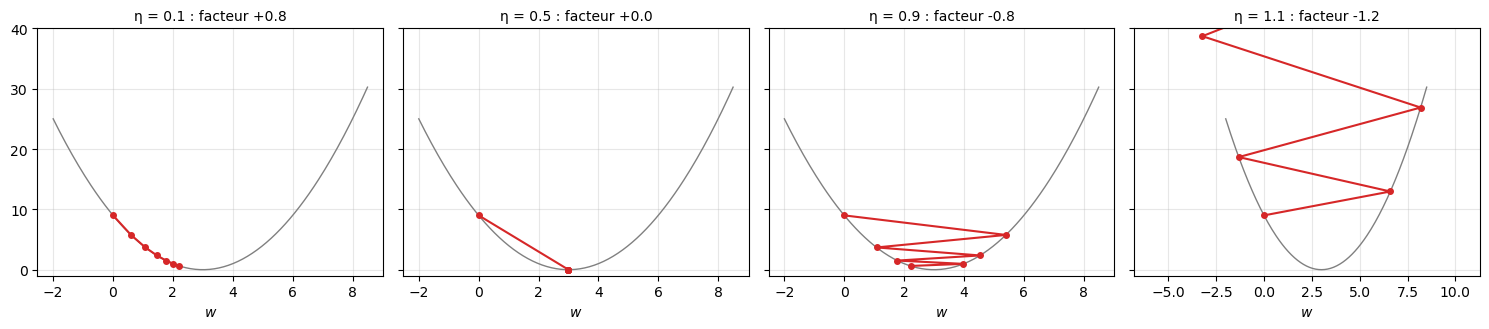

Le facteur (1 - 2η) multiplie l'écart au minimum à chaque pas : il converge si |1 - 2η| < 1, soit 0 < η < 1.


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
ww = np.linspace(-2, 8.5, 200)
for ax, eta in zip(axes, (0.1, 0.5, 0.9, 1.1)):
    s = np.array(descente(eta, 6))
    ax.plot(ww, (ww - 3) ** 2, color="gray", lw=1)
    ax.plot(s, (s - 3) ** 2, "o-", color="C3", ms=4)
    facteur = 1 - 2 * eta
    ax.set_title(f"η = {eta} : facteur {facteur:+.1f}", fontsize=10); ax.set_ylim(-1, 40); ax.set_xlabel("$w$")
plt.tight_layout(); plt.show()
print("Le facteur (1 - 2η) multiplie l'écart au minimum à chaque pas : il converge si |1 - 2η| < 1, soit 0 < η < 1.")

## Partie C — Exercices de validation

Chaque fonction ci-dessous renvoie `None` : le vérificateur affiche alors **« À compléter »**. Complétez-les, puis relancez `verifier_tout()`. Le corrigé est à la fin du notebook : essayez d'abord !

In [17]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
        return
    try:
        ok = np.allclose(np.asarray(valeur, dtype=float), np.asarray(attendu, dtype=float), atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {np.round(np.asarray(valeur, dtype=float), 4)}, attendu {attendu})")

def verifier_tout():
    verifier("Exercice 1 — neurone", neurone([2.0, 1.0], [0.5, -1.0], 0.5), 0.6225)
    r = maj_perceptron(np.array([0.0, 0.0]), -1.0, np.array([1.0, 1.0]), 1.0, 1.0)
    verifier("Exercice 2 — perceptron", None if r is None else np.append(r[0], r[1]), [1.0, 1.0, 0.0])
    verifier("Exercice 3 — softmax", softmax([2.0, 1.0, 0.0]), [0.6652, 0.2447, 0.0900])
    verifier("Exercice 3 bis — softmax stable", softmax([1000.0, 1001.0]), [0.2689, 0.7311])
    verifier("Exercice 4 — Huber", huber_moyenne([0.5, -0.5, 1.0, 10.0], 1.0), 2.5625)
    verifier("Exercice 5 — descente", descente_k(0.1, 3), 1.464)
    verifier("Exercice 5 bis — divergence", descente_k(1.1, 3), 8.184)

**Exercice 1 — Neurone.** Complétez `neurone(x, w, b)` : la sortie $\sigma(\mathbf{w}^\top\mathbf{x} + b)$. Puis, en dehors du vérificateur : que vaut la sortie si $b = -10$ ?

In [18]:
def neurone(x, w, b):
    # À compléter
    return None

**Exercice 2 — Une correction du perceptron.** Complétez `maj_perceptron(w, b, x, y, eta)` : elle renvoie le couple `(w, b)` après présentation de l'exemple `(x, y)`, avec la règle de Rosenblatt. Attention : $\hat y = \mathrm{step}(\mathbf{w}^\top\mathbf{x} + b)$ vaut 1 quand $z \ge 0$.

In [19]:
def maj_perceptron(w, b, x, y, eta):
    # À compléter : renvoyer (nouveau_w, nouveau_b)
    return None

**Exercice 3 — Softmax stable.** Complétez `softmax(z)`. Elle doit rester correcte pour `z = [1000, 1001]` : pensez à soustraire le maximum.

In [20]:
def softmax(z):
    # À compléter
    return None

**Exercice 4 — Perte de Huber moyenne.** Complétez `huber_moyenne(e, delta)` : la moyenne de $H_\delta(e_i)$.

In [21]:
def huber_moyenne(e, delta):
    # À compléter
    return None

**Exercice 5 — Descente de gradient.** Complétez `descente_k(eta, k)` : la valeur $w_k$ après $k$ pas sur $f(w) = (w-3)^2$, en partant de $w_0 = 0$. Puis, en dehors du vérificateur : pour quelle valeur de $\eta$ converge-t-on en un seul pas ?

In [22]:
def descente_k(eta, k):
    # À compléter
    return None

In [23]:
verifier_tout()

Exercice 1 — neurone : À compléter
Exercice 2 — perceptron : À compléter
Exercice 3 — softmax : À compléter
Exercice 3 bis — softmax stable : À compléter
Exercice 4 — Huber : À compléter
Exercice 5 — descente : À compléter
Exercice 5 bis — divergence : À compléter


## Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance le vérificateur.

In [24]:
def neurone(x, w, b):
    return float(sigmoide(np.dot(w, x) + b))          # avec b = -10 : sigma(-10,5) ≈ 2,8e-5, le neurone est « éteint »

def maj_perceptron(w, b, x, y, eta):
    y_hat = float(np.dot(w, x) + b >= 0)
    return np.asarray(w, dtype=float) + eta * (y - y_hat) * np.asarray(x, dtype=float), b + eta * (y - y_hat)

def softmax(z):
    e = np.exp(np.asarray(z, dtype=float) - np.max(z))   # soustraire le maximum évite le débordement
    return e / e.sum()

def huber_moyenne(e, delta):
    e = np.asarray(e, dtype=float)
    return float(np.mean(np.where(np.abs(e) <= delta, 0.5 * e ** 2, delta * (np.abs(e) - delta / 2))))

def descente_k(eta, k):
    w = 0.0
    for _ in range(k):
        w = w - eta * 2 * (w - 3)
    return w                                          # eta = 0,5 : le facteur 1 - 2 eta vaut 0, minimum atteint en un pas

verifier_tout()

Exercice 1 — neurone : Correct
Exercice 2 — perceptron : Correct
Exercice 3 — softmax : Correct
Exercice 3 bis — softmax stable : Correct
Exercice 4 — Huber : Correct
Exercice 5 — descente : Correct
Exercice 5 bis — divergence : Correct


## Pour aller plus loin

- **TensorFlow Playground** (`playground.tensorflow.org`) : entraînez un petit MLP dans le navigateur et voyez XOR résolu dès que vous ajoutez une couche cachée.
- Remplacez la perte du neurone AI4I par la MAE : que se passe-t-il pour une classification ?
- Calculez à la main $\partial\mathcal{L}/\partial w$ pour le réseau 2-2-1 : c'est la **séance 3**.

## Références

- Rosenblatt (1958), *The Perceptron* ; Minsky et Papert (1969), *Perceptrons* ; Novikoff (1962), théorème de convergence du perceptron.
- Cybenko (1989) et Hornik (1991) : approximation universelle ; Hendrycks et Gimpel (2016) : GELU ; Amin et al. (1997) : sigmoïde linéaire par morceaux (PLAN).
- Matzka (2020), *AI4I 2020 Predictive Maintenance Dataset*, UCI, CC BY 4.0.

In [25]:
print(f"Durée d'exécution du notebook : {time.time() - T0:.0f} s")

Durée d'exécution du notebook : 4 s
